Markdown
#Group Information 
Members: Shishir, Royar, Hashir
Members Name: Shishir Dahal
Student ID: 313101

Markdown
#Task I.1 - Problem Description and Dataset (Paderborn University Bearing Data)

1. Description of Engineering System, Measurements and Data Origin

(i) Engineering System:
 The engineering system is an accelerated lifetime test rig (Test Setup KA) developed by the Chair of Design and Drive Technology at Paderborn University. The test rig consists of a test motor module, a measuring shaft module, a radial force module, a flywheel module, and a load motor module. The setup is designed to investigate bearing degradation and fault development under controlled operating conditions.
(ii) Measurements and Sensors:
A high-frequency multi-sensor data acquisition system records physical parameters during bearing operation. The available measurements include:

Vibration signals
Motor current signals
Load force
Torque
Rotational speed
Temperature
These measurements provide information about both operating conditions and bearing health.
(iii) Data Origin:
The dataset contains measurements from deep-groove ball bearings operating under various predefined load and heating conditions (K0, K1, K2 and K3). For this study, recordings from three bearing states were selected:

K001: Healthy bearing
KA01: Outer-ring fault bearing
KI01: Inner-ring fault bearing

The damaged bearings contain artificially introduced defects produced using Electrical Discharge Machining (EDM). The dataset used in this project consists of 240 recordings in total (80 K001, 80 KA01 and 80 KI01 recordings).

2. Description of Input Features and Classification Targets

(i) Input Features: The complete Paderborn dataset contains vibration signals, motor-current measurements and operating-condition variables such as speed, temperature, load and torque.

In this project, only the vibration_1 signal was used. Each vibration recording was divided into non-overlapping segments of 2000 samples, and the following time-domain features were extracted:

Root Mean Square (RMS)
Peak amplitude
Crest Factor
Kurtosis

These features were used as inputs to the machine-learning models..
(ii) Classification Targets: 
The classification target is the bearing health condition. The problem is formulated as a multi-class classification task with three classes:
Class         Bearing Condition
K001          Healthy Bearing
KA01          Outer-ring fault (EDM defect)
KI01          Inner-ring fault (EDM defect)
The objective is to automatically determine the bearing condition and fault location from vibration measurements.

3. Engineering Relevance of the Classification Problem
Rolling bearings are critical components in industrial rotating machinery. Bearing failures can lead to:

Unexpected equipment breakdowns
Production downtime
Increased maintenance costs
Reduced system reliability

Automated bearing fault classification supports predictive maintenance by identifying faults before catastrophic failure occurs. Accurate condition monitoring reduces maintenance costs and improves operational reliability in industrial drive systems.

4. Dataset Citation, URL, and License
 Dataset Name:
 Paderborn University Bearing Data Center Dataset

Authors:
 Prof. Dr.-Ing. Detmar Zimmer, Christian Lessmeier, Waldemar Dück and Stefan Brocke
 Chair of Design and Drive Technology, Paderborn University

URL:
 https://mb.uni-paderborn.de/en/kat/research/kat-datacenter/bearing-datacenter

License and Usage:
 The dataset is a publicly available research benchmark dataset intended for scientific research, fault diagnosis development, condition monitoring studies and machine-learning applications.


K001 files: 80
KA01 files: 80
KI01 files: 80
K001: 80 files found
KA01: 80 files found
KI01: 80 files found
Shape (rows, columns): (30743, 7)

Data types:
 recording         int64
piece             int64
label             int64
rms             float64
peak            float64
crest_factor    float64
kurtosis        float64
dtype: object

Missing values:
 recording       0
piece           0
label           0
rms             0
peak            0
crest_factor    0
kurtosis        0
dtype: int64

Duplicate rows: 0

Class counts:
 label
Outer race    10255
Healthy       10246
Inner race    10242
Name: count, dtype: int64

Summary statistics:
              rms       peak  crest_factor   kurtosis
count  30743.000  30743.000     30743.000  30743.000
mean       0.472      3.590         7.591     15.139
std        0.141      1.383         1.344      4.596
min        0.165      1.221         4.360      5.523
25%        0.377      2.707         6.588     12.101
50%        0.464      3.342         7.

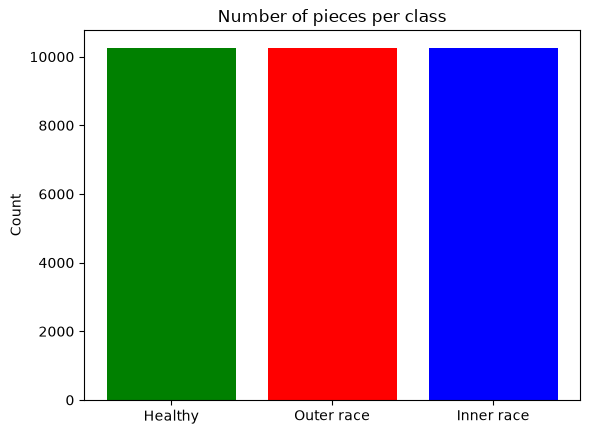

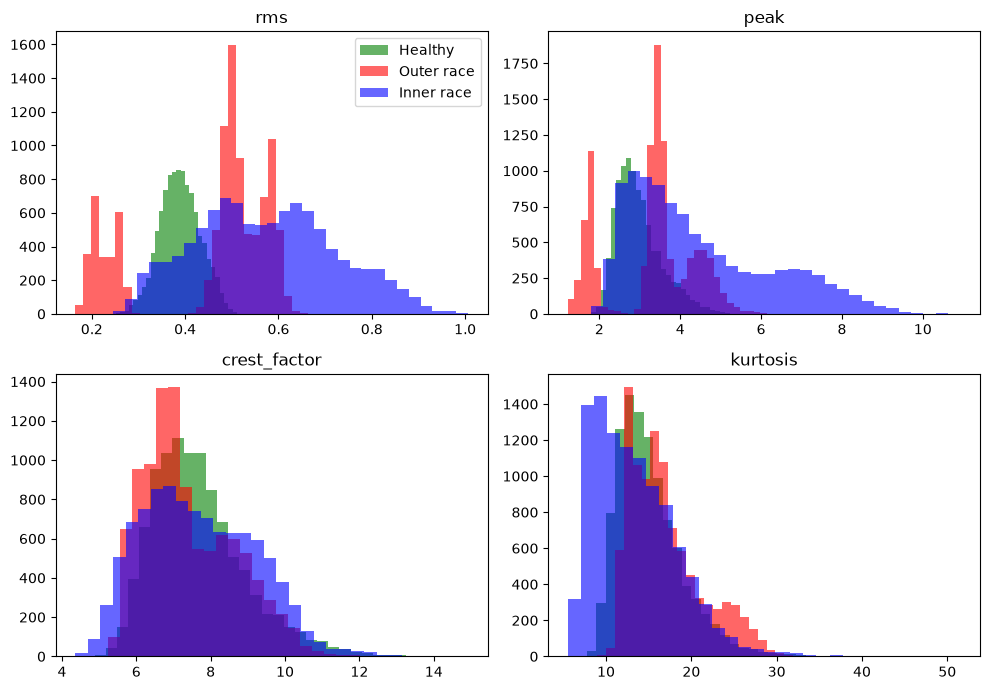

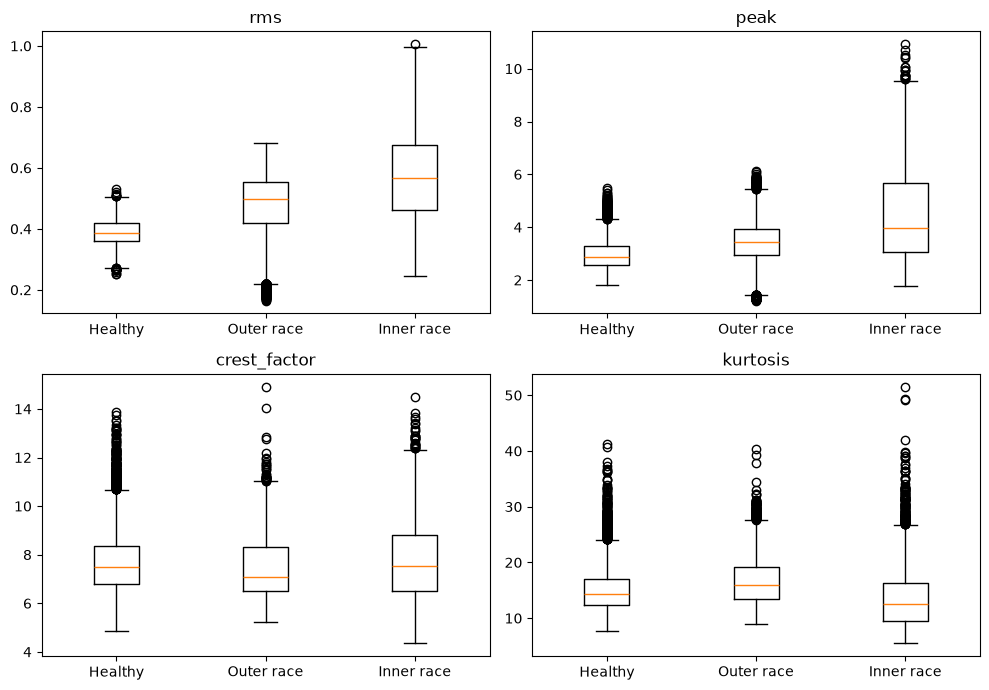

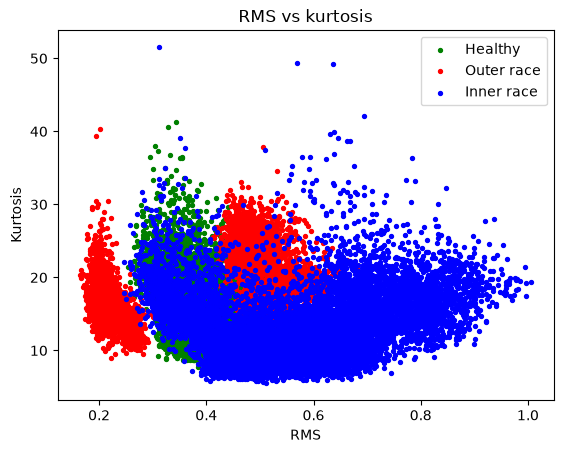


Train size: 24593  Test size: 6150
Train means after scaling (should be ~0): [-0.  0. -0. -0.]
Train std after scaling (should be ~1): [1. 1. 1. 1.]
Test rows that also appear in the training set: 0

Baseline accuracy to beat: 0.334
no scaling     train F1 0.799 | test accuracy 0.805 | test macro F1 0.808
StandardScaler train F1 0.913 | test accuracy 0.917 | test macro F1 0.916


In [3]:
# Task I.2 : explore, clean and prepare bearing vibration data
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

DATA_DIR = r"C:\Users\shishir\OneDrive\Desktop\MOD550 A3\Data set"
os.makedirs("figures", exist_ok=True)

# Use ALL recordings for each bearing class
CLASS_PATTERNS = {
    'K001': (0, '*K001*.mat'),
    'KA01': (1, '*KA01*.mat'),
    'KI01': (2, '*KI01*.mat')
}

NAMES = {
    0: 'Healthy',
    1: 'Outer race',
    2: 'Inner race'
}
print("K001 files:", len(glob.glob(os.path.join(DATA_DIR, "**", "*K001*.mat"), recursive=True)))
print("KA01 files:", len(glob.glob(os.path.join(DATA_DIR, "**", "*KA01*.mat"), recursive=True)))
print("KI01 files:", len(glob.glob(os.path.join(DATA_DIR, "**", "*KI01*.mat"), recursive=True)))

# ---------------------------------------------------------------- STEP 1: load
def load_signal(path):
    """Open a .mat file and return the vibration_1 signal as a list of numbers."""
    m = scipy.io.loadmat(path, squeeze_me=True, struct_as_record=False)
    key = [k for k in m if not k.startswith('__')][0]
    channel_names = [y.Name for y in m[key].Y]
    return np.asarray(m[key].Y[channel_names.index('vibration_1')].Data, float).ravel()

rows = []

for code, (label, pattern) in CLASS_PATTERNS.items():

    files = glob.glob(
        os.path.join(DATA_DIR, '**', pattern),
        recursive=True
    )

    print(f"{code}: {len(files)} files found")

    for file_id, path in enumerate(files):

        signal = load_signal(path)

        # Cut each recording into pieces of 2000 samples
        for i in range(len(signal) // 2000):

            piece = signal[i * 2000:(i + 1) * 2000]

            rms = np.sqrt(np.mean(piece ** 2))
            peak = np.max(np.abs(piece))

            mean = piece.mean()
            std = piece.std()

            if std == 0:
                continue

            kurtosis = np.mean(((piece - mean) / std) ** 4)

            rows.append({
                'recording': file_id,      # NEW
                'piece': i,
                'label': label,
                'rms': rms,
                'peak': peak,
                'crest_factor': peak / rms,
                'kurtosis': kurtosis
            })

df = pd.DataFrame(rows)
features = ['rms', 'peak', 'crest_factor', 'kurtosis']

# ------------------------------------------------- STEP 2: basic inspection
print("Shape (rows, columns):", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass counts:\n", df['label'].map(NAMES).value_counts())
print("\nSummary statistics:\n", df[features].describe().round(3))

# Lecture point: "accuracy lies" - compare with the baseline of always guessing
# the biggest class. A model must beat this to be useful.
baseline = df['label'].value_counts(normalize=True).max()
print("\nBaseline accuracy (always guess the biggest class):", round(baseline, 3))

# Lecture point: scale matters. Ratio of largest to smallest feature spread.
stds = df[features].std()
print("Feature std:\n", stds.round(4))
print("Largest : smallest std =", round(stds.max() / stds.min(), 1), ": 1")

# ------------------------------------ STEP 3: impossible values (physics rules)
# These can never happen with real data, so they must be errors.
impossible = (df['rms'] <= 0) | (df['crest_factor'] < 1) | (df['kurtosis'] < 1)
print("\nImpossible rows found:", impossible.sum())
df = df[~impossible]                                  # keep only the possible rows

# duplicates leak. If one copy lands in train and another in test,
# the model is tested on rows it has already seen. Drop them BEFORE splitting.
# (We ignore the 'piece' number so identical measurements count as duplicates.)
n_before = len(df)
df = df.drop_duplicates(subset=features + ['label'])
print("Duplicate rows removed before the split:", n_before - len(df))

# ------------------------------- STEP 4: outliers (unusual but possible values)
# IQR rule: a value is an outlier if it is far outside the middle 50% of the data.
for f in features:
    q1, q3 = df[f].quantile(0.25), df[f].quantile(0.75)
    iqr = q3 - q1
    n_out = ((df[f] < q1 - 1.5 * iqr) | (df[f] > q3 + 1.5 * iqr)).sum()
    print(f"Outliers in {f}: {n_out}")
# We KEEP outliers: sudden spikes are exactly what a damaged bearing produces.

# --------------------------------------------- STEP 5: class relationships
print("\nAverage of each feature per class:\n",
      df.groupby('label')[features].mean().round(3))
print("\nCorrelation between features:\n", df[features].corr().round(2))

# ------------------------------------------------------ STEP 6: figures
colors = {0: 'green', 1: 'red', 2: 'blue'}

# Figure 1: is the data balanced?
counts = df['label'].value_counts().sort_index()
plt.bar([NAMES[k] for k in counts.index], counts.values,
        color=[colors[k] for k in counts.index])
plt.title('Number of pieces per class'); plt.ylabel('Count')
plt.savefig('figures/fig1_class_balance.png'); plt.show()

# Figure 2: histograms - how are values spread, per class?
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, f in zip(axes.ravel(), features):
    for label in [0, 1, 2]:
        ax.hist(df[df.label == label][f], bins=30, alpha=0.6,
                color=colors[label], label=NAMES[label])
    ax.set_title(f)
axes[0, 0].legend()
plt.tight_layout(); plt.savefig('figures/fig2_histograms.png'); plt.show()

# Figure 3: boxplots - spread and outliers per class
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, f in zip(axes.ravel(), features):
    ax.boxplot([df[df.label == k][f] for k in [0, 1, 2]],
               tick_labels=[NAMES[k] for k in [0, 1, 2]])
    ax.set_title(f)
plt.tight_layout(); plt.savefig('figures/fig3_boxplots.png'); plt.show()

# Figure 4: can two features separate the classes?
for label in [0, 1, 2]:
    d = df[df.label == label]
    plt.scatter(d['rms'], d['kurtosis'], s=8, color=colors[label], label=NAMES[label])
plt.xlabel('RMS'); plt.ylabel('Kurtosis'); plt.legend(); plt.title('RMS vs kurtosis')
plt.savefig('figures/fig4_scatter.png'); plt.show()

# ----------------------------------------------------- STEP 7: preprocessing
# (a) Split into train (first 80% of each class) and test (last 20%).
#     We cut in time order instead of randomly, because neighbouring pieces of
#     the same recording look very alike - a random split would let the test
#     data "leak" into training.
train_parts, test_parts = [], []
for label in [0, 1, 2]:
    d = df[df.label == label].sort_values('piece')
    cut = int(len(d) * 0.8)
    train_parts.append(d.iloc[:cut]); test_parts.append(d.iloc[cut:])
train, test = pd.concat(train_parts), pd.concat(test_parts)
print("\nTrain size:", len(train), " Test size:", len(test))

# (b) Imputation: fill missing values with the median (we found none, but this
#     makes the pipeline safe). Learn the median from TRAIN data only.
imputer = SimpleImputer(strategy='median').fit(train[features])
X_train = imputer.transform(train[features])
X_test = imputer.transform(test[features])

# (c) Scaling: rms is around 0.2 but kurtosis can be 10, so many models would
#     treat kurtosis as "more important". StandardScaler gives every feature
#     mean 0 and standard deviation 1. Again, learn it from TRAIN data only.
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)
y_train, y_test = train['label'].values, test['label'].values

print("Train means after scaling (should be ~0):", X_train.mean(axis=0).round(2))
print("Train std after scaling (should be ~1):", X_train.std(axis=0).round(2))

# Leakage check : how many test rows also appear in train?
leak = test[features].round(8).merge(train[features].round(8), how='inner').shape[0]
print("Test rows that also appear in the training set:", leak)

# (d) Feature engineering: crest_factor (peak / rms) was created from existing
#     columns because it highlights spikes relative to normal vibration.

# ------------------------------------- STEP 8: quick check with an SVM
# Why scaling matters, shown with numbers (same idea as the lecture's wine example).
# We report macro F1 (every class counts equally) next to accuracy.
raw_train, raw_test = train[features].values, test[features].values

def evaluate(name, Xa, Xb):
    model = SVC(kernel='rbf', C=1.0, gamma='scale').fit(Xa, y_train)
    print(f"{name:14s} train F1 {f1_score(y_train, model.predict(Xa), average='macro'):.3f} | "
          f"test accuracy {accuracy_score(y_test, model.predict(Xb)):.3f} | "
          f"test macro F1 {f1_score(y_test, model.predict(Xb), average='macro'):.3f}")

print("\nBaseline accuracy to beat:", round(baseline, 3))
evaluate("no scaling", raw_train, raw_test)
evaluate("StandardScaler", X_train, X_test)


Markdown
#Task I.2: Data Exploration and Preparation: Observations

1. Data inspection and quality checks. The complete dataset contains 240 recordings (80 Healthy, 80 Outer-race fault, and 80 Inner-race fault recordings). Each vibration recording was divided into non-overlapping windows of 2000 samples, and four statistical features (RMS, Peak, Crest Factor, and Kurtosis) were extracted from each segment.

The resulting feature matrix contains 30,743 rows and 7 columns. Each row represents one vibration segment and contains a recording identifier, segment index, class label, and four extracted features. All features are numeric (float64 for measurements and int64 for identifiers).

There are no missing values and no duplicate rows. The classes are approximately balanced:

Healthy: 10,246 segments
Outer race: 10,255 segments
Inner race: 10,242 segments

The majority-class baseline accuracy is 0.334, indicating that any useful classification model must perform substantially better than simple majority-class prediction. No resampling was required due to the near-perfect class balance.

2. Anomalies and impossible values. Three physical validity rules were checked:

RMS ≤ 0
Crest Factor < 1
Kurtosis < 1
No observations violated these rules:
    Impossible rows found: 0
Outliers were identified using the 1.5 × IQR rule.
Feature             Outliers
RMS	                 489
Peak	             2,061
Crest Factor	     258
Kurtosis	         883

Peak amplitude produced the highest number of outliers. Many of these observations correspond to genuine fault-related vibration impacts rather than measurement errors. The outliers were therefore retained because they may contain important diagnostic information for fault classification.

3. Distributions and class relationships. Feature scales differ considerably. The largest standard deviation (Kurtosis = 4.596) is approximately 32.5 times larger than the smallest (RMS = 0.141), which strongly motivates feature scaling before machine-learning modelling.

Average feature values for each class are:
Class	      RMS	   Peak	    Crest Factor	 Kurtosis
Healthy	      0.389	   2.982	  7.681	         15.094
Outer Race	  0.453	   3.306	  7.405	         16.950
Inner Race	  0.573	   4.484	  7.687	         13.371

Several trends are visible:

RMS increases from Healthy → Outer Race → Inner Race.
Peak amplitude is highest for Inner Race faults.
Outer-race faults exhibit the highest average kurtosis.
Crest Factor differs less strongly between classes.

Feature correlations show:
Feature Pair	         Correlation
RMS - Peak	               0.86
Peak - Crest Factor	       0.53
Crest Factor - Kurtosis    0.77
RMS - Kurtosis	          -0.08
RMS and Peak are strongly related to vibration severity, while Crest Factor and Kurtosis describe impulsive fault behaviour.

4. Visualizations and diagnostic findings.

Histograms (fig2_histograms.png): The histograms show clear differences between the three bearing conditions.

RMS provides strong class separation. Healthy bearings occupy lower RMS values, outer-race faults occupy an intermediate range, and inner-race faults extend to the highest RMS values, reaching approximately 1.0.
Peak amplitude exhibits a similar trend. Healthy bearings generally produce lower peaks, while inner-race faults generate substantially larger peaks, exceeding 10 in some cases.
Crest Factor distributions overlap considerably across the three classes and therefore provide weaker discrimination when used alone.
Kurtosis distributions also overlap, although outer-race faults tend to exhibit slightly larger values than the other classes.

Overall, RMS and Peak provide the clearest class separation.

Boxplots (fig3_boxplots.png): The boxplots confirm that:

RMS median values increase from Healthy → Outer Race → Inner Race.
Peak median values show the same behaviour.
Inner-race faults exhibit the largest spread in RMS and Peak, indicating greater variability in vibration severity.
Crest Factor distributions overlap considerably across classes.
Outer-race faults show the highest median kurtosis values, while inner-race faults exhibit the lowest median kurtosis.

These observations are consistent with the class means and indicate that RMS and Peak are the most informative features for fault discrimination.

The RMS-kurtosis scatter plot: The RMS-kurtosis scatter plot indicates that RMS contributes much more strongly to class separation than kurtosis.

Healthy observations are concentrated at lower RMS values.
Outer-race faults occupy an intermediate RMS region.
Inner-race faults extend toward higher RMS values and exhibit substantially greater variability.

Although some separation exists, significant overlap remains between classes, particularly in kurtosis. Consequently, the classes are not perfectly linearly separable in the RMS-kurtosis feature space, supporting the use of a non-linear classifier such as an RBF-kernel SVM.

Overall, RMS and Peak provide the strongest visible separation between bearing conditions.

5. Preprocessing.

Split: The dataset was divided chronologically within each class:

Training set: 24,593 observations
Testing set: 6,150 observations

The first 80% of observations per class were assigned to the training set and the remaining 20% were reserved for testing. This approach reduces the likelihood of neighbouring signal segments appearing in both datasets.

A leakage check found:
    Test rows that also appear in the training set: 0

Imputation: A median imputer was included as a safeguard, although no missing values were present in the dataset.

Feature Engineering: Crest Factor was derived from existing measurements:

        Crest factor= Peak/RMS
This feature highlights impact-type behaviour relative to normal vibration levels.

Scaling: StandardScaler was fitted on the training data only and applied to both the training and testing sets.

After scaling:
Train means ≈ [0,0,0,0]
Train standard deviations ≈ [1,1,1,1]
confirming successful standardization.

Initial SVM Validation: An RBF-kernel SVM was trained to evaluate the usefulness of the extracted features.
Without Scaling:
                Train Macro F1 = 0.799
                Test Accuracy = 0.805
                Test Macro F1 = 0.808

With StandardScaler:
                Train Macro F1 = 0.913
                Test Accuracy = 0.917
                Test Macro F1 = 0.916
Feature scaling improved:

Accuracy from 0.805 to 0.917
Macro F1 from 0.808 to 0.916

demonstrating that standardization is essential for SVM-based fault diagnosis and that the extracted vibration features contain substantial information about bearing condition.


6. Limitation: Although the dataset now includes 240 recordings, the train-test split is still performed at the segment level rather than the recording level. Segments originating from the same recording may therefore appear in both the training and testing sets. While direct duplicate observations were not present, recording-specific characteristics may still be shared across the split.

A more rigorous evaluation would perform the split at the recording level, ensuring that entire recordings are held out during testing. This would provide a stronger assessment of how well the model generalises to completely unseen bearing measurements.

In [5]:
# Task I.3: Classification Strategy and Baseline

from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# 5-fold stratified cross-validation
# No shuffling is used because neighbouring vibration segments
# may be highly similar.
cv = StratifiedKFold(n_splits=5, shuffle=False)

# SVM pipeline: scaling + RBF SVM
pipe = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf')
)

svm_scores = cross_val_score(
    pipe,
    train[features],
    y_train,
    cv=cv,
    scoring='f1_macro'
)

print("SVM CV macro F1:", svm_scores.round(3))
print("Mean SVM macro F1:", round(svm_scores.mean(), 3))

# Majority-class baseline
dummy = DummyClassifier(strategy='most_frequent')

dummy_scores = cross_val_score(
    dummy,
    train[features],
    y_train,
    cv=cv,
    scoring='f1_macro'
)

print("Baseline CV macro F1:", dummy_scores.round(3))
print("Mean baseline macro F1:", round(dummy_scores.mean(), 3))

SVM CV macro F1: [0.917 0.912 0.91  0.911 0.912]
Mean SVM macro F1: 0.912
Baseline CV macro F1: [0.167 0.167 0.167 0.167 0.167]
Mean baseline macro F1: 0.167


Markdown
#Task I.3: Classification Strategy and Baseline
The dataset contains 240 recordings (80 Healthy, 80 Outer-race fault and 80 Inner-race fault recordings) segmented into 30,743 vibration windows. The data was split in time order within each class, with the first 80% used for training and the final 20% reserved for testing, resulting in 24,593 training samples and 6,150 test samples. Model selection and validation were performed using 5-fold Stratified Cross-Validation on the training data only.

Potential sources of data leakage included neighbouring vibration segments appearing across splits, duplicate observations, scaling performed on the full dataset, and tuning based on test-set performance. These risks were reduced through time-ordered splitting, duplicate removal before splitting, fitting the StandardScaler only within the training folds through a pipeline, and keeping the test set untouched until final evaluation. A leakage check confirmed that 0 test rows also appeared in the training set.

The primary model-selection metric was Macro F1-score, because it gives equal importance to Healthy, Outer-race and Inner-race classes. The baseline DummyClassifier achieved a mean cross-validation Macro F1 of 0.167, whereas the RBF-kernel SVM achieved a mean Macro F1 of 0.912, demonstrating strong fault-classification capability.

MarkDown
Task I.4: SVM Modeling

In [ ]:
#Task I.4: SVM Modeling

Explanation of kernel/hyperparameter choices

MarkDown
Task I.5 -- Model Evaluation 


In [ ]:
#Task I.5 -- Model Evaluation

MarkDown
Evaluation and comparison against the baseline

#Individual Analysis -- Shishir Dahal 